# Smart Firewall with Deep Learning for Intrusion Detection
### CMP403 Honours Dissertation — Abertay University




Introduction
-----------------------------

## Notebook Overview

This notebook implements a machine learning pipeline for multiclass network intrusion detection. It forms the practical component of the dissertation *"Machine Learning Based Firewall: A Practical Machine Learning Application in Cyber Defence"*.

The pipeline attempts a reliable automated classification of network traffic into benign and attack categories, including rare and difficult-to-detect attack classes, under severe class imbalance found in the LyCoS-Unicas-2018 dataset.

---

## Pipeline Structure

The notebook is organised into the following sequential stages:

| Stage | Description |
|---|---|
| **1. Data Loading** | Dataset Loading and execution of stratified sampling which keeps class proportions |
| **2. Preprocessing** | Rare class filtering, label encoding, and three-way stratified split  |
| **3. Feature Selection** | RFECV with permutation importance and macro F1 scoring, reducing 77 features to subset containing 56 |
| **4. XGBoost** | Gradient boosted tree classifier with balanced sample weighting and early stopping on validation loss |
| **5. TabTransformer** | PyTorch attention-based deep learning xgb_model with weighted cross-entropy loss and early stopping on validation F1 Macro |
| **6. Evaluation** | overall and perclass classification reports, confusion matrices, and precision-recall curves |
| **7. Storage** | Serialisation of all models and preprocessing artifacts |
| **8. Deployment** | Loading and execution of serialised models|
---

## Inference 
For inference, jump directly to chapter 7 and 8.
Ensure all files are in the proper place (found inside **id_artefacts.zip** and **loadset_dataset.zip**).
## Dataset

**LyCoS-Unicas-IDS2018** (Cantone et al., 2024) is  a corrected derivation of the CSE-CIC-IDS2018 dataset. It includes 13,691,268  records and  10 attack categories.
Features are extracted by using LycoSTand, addressing known labelling and flow generation errors present in the original dataset which used  CICFlowMeter.

Attack categories: `Benign`, `Bot`, `DDoS HOIC`, `DDoS LOIC-HTTP`, `DoS GoldenEye`, `DoS Hulk`, `DoS Slowhttptest`, `DoS Slowloris`, `FTP-Patator`, `SSH-Patator`

---

## Key Design Decisions

- **Macro F1 as the primary metric** — overall accuracyis heavily influenced by the Benign majority class (73% of data) making Macro F1 the best metric as it handles class imbalance much better
- **Permutation importance over MDI** permutation importance with macro F1 scoring is used instead of impurity based RFECV to avoid bias towards the high caridanlity class (Strobl et al., 2007)
- **Three-way split** keeps the test set entirely unseen during all training and tuning decisions (Kaufman et al., 2012)


---



## Libraries import

In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import joblib
import os
import gc
import warnings
from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFECV
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import (compute_sample_weight,
                                         compute_class_weight)
from sklearn.metrics import (classification_report,
                             confusion_matrix,
                             ConfusionMatrixDisplay,
                             roc_auc_score,
                             matthews_corrcoef,
                             f1_score)


iskaggle = os.environ.get('KAGGLE_KERNEL_RUN_TYPE', '')
if iskaggle: path = Path('/kaggle/input/datasets/username/lycos-unicas-2018/') #Change *Username* to your username IF USING KAGGLE
else:
    path = Path('Dataset') #If not Kaggle, use "Dataset" folder 
    if not path.exists(): #If folder is not found to be existant
        import zipfile,kaggle #Import required python packages
        kaggle.api.competition_download_cli(str(path)) 
        zipfile.ZipFile(f'{path}.zip').extractall(path) #extract dataset
#-----------------------------
import torch, numpy as np, pandas as pd
np.set_printoptions(linewidth=140)
torch.set_printoptions(linewidth=140, sci_mode=False, edgeitems=7)
pd.set_option('display.width', 140)

#Unused Libraries, kept for reference
#from fastai.text.all import *
#from fastai.collab import *
#from fastai.tabular.all import *

## Stratified Sampling 



- **100,000-row sample** — the full LyCoS-Unicas-IDS2018 dataset contains 13,691,268 rows. Training on the full dataset would have exceeded system memory limits and substantially increase RFECV amount of compuation required. 100,000 rows provides sufficient representation of all attack classes whilst remaining computationally tractable.
- **Stratified sampling** ensures training and testing sets maintain the same minority-to-majority class ratio preventing biased models

In [2]:
# STRATIFIED SAMPLING
dataframe = pd.read_csv(path/'LycoS-Unicas-IDS2018.csv')
SAMPLE_SIZE = 100_000
dataframe = dataframe.groupby('label', group_keys=False).apply(
    lambda x: x.sample(
        min(len(x), max(1, int(SAMPLE_SIZE * len(x) / len(dataframe)))), #stratified sampling algorithm
        random_state=42 #Used 42 for all random states. To ensure reproducibility 
    )
).reset_index(drop=True)

/tmp/ipykernel_170/3144969819.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  dataframe = dataframe.groupby('label', group_keys=False).apply(


In [3]:
dataframe #Shape of loaded tabular NIDS datset

,dst_port,ip_prot,flow_duration,down_up_ratio,pkt_len_max,pkt_len_min,pkt_len_mean,pkt_len_var,pkt_len_std,bytes_per_s,...,bwd_bulk_bytes_mean,bwd_bulk_pkt_mean,bwd_bulk_rate_mean,fwd_subflow_bytes_mean,fwd_subflow_pkt_mean,bwd_subflow_bytes_mean,bwd_subflow_pkt_mean,fwd_tcp_init_win_bytes,bwd_tcp_init_win_bytes,label
0,3389,6,2364960,0.875000,1173.0,0.0,181.933333,107109.495238,327.275870,1153.930722,...,0.0,0.0,0.0,1148.000000,8.000000,1581.000000,7.000000,8192,64000,Benign
1,443,6,9011738,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.000000,1.000000,0.000000,0.000000,8192,-1,Benign
2,53,17,1083,1.000000,62.0,30.0,46.000000,512.000000,22.627417,84949.215143,...,0.0,0.0,0.0,30.000000,1.000000,62.000000,1.000000,-1,-1,Benign
3,445,6,802330,0.833333,147.0,0.0,70.090909,3735.890909,61.121935,960.951230,...,0.0,0.0,0.0,455.000000,6.000000,316.000000,5.000000,8192,8192,Benign
4,443,6,21218904,1.000000,1410.0,0.0,208.350000,179797.502632,424.025356,196.381491,...,0.0,0.0,0.0,285.000000,5.000000,1798.500000,5.000000,8192,28200,Benign
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99990,22,6,384205,0.869565,976.0,0.0,107.558140,42963.062016,207.275329,12037.844380,...,0.0,0.0,0.0,1960.000000,23.000000,2665.000000,20.000000,26883,26847,SSH-Patator
99991,22,6,401660,0.833333,976.0,0.0,105.113636,42226.847252,205.491721,11514.713937,...,0.0,0.0,0.0,1960.000000,24.000000,2665.000000,20.000000,26883,26847,SSH-Patator
99992,80,6,56463629,0.679739,1068.0,0.0,496.015564,125825.343507,354.718682,2257.665727,...,0.0,0.0,0.0,1078.333333,3.000000,1421.196078,2.039216,8192,26883,Web Attack - Brute Force
99993,80,6,5009865,1.000000,630.0,0.0,144.750000,72580.500000,269.407684,231.143953,...,0.0,0.0,0.0,315.000000,2.000000,264.000000,2.000000,8192,26883,Web Attack - Sql Injection



## Preprocessing
------------------------------------



- **Rare class threshold of 35** — classes with fewer than 35 samples after stratified sampling are removed. With a 70/15/15 split, a class with fewer than 35 samples would have fewer than 6 test instances, making per-class evaluation metrics unreliable. 
- **Data quality diagnostic before cleaning** — NaN, infinity, and zero-variance checks are run. 
- **NaN/Inf handling kept as commented code** — the replacement cell is intentionally left commented out because the diagnostic confirmed no NaN or Inf values exist in this dataset. Applying `fillna` when no values are missing would be unnecessary.
- **Three-way stratified split (70/15/15)** — a dedicated validation set is used to prevent data leakage. 

In [4]:
#RARE CLASSES HANDLING, ELIMINATION OF CLASSES WITH LESS THAN 35 SAMPLES
class_counts = dataframe['label'].value_counts()
rare_classes = class_counts[class_counts < 35].index
print(f"Removing {len(rare_classes)} rare classes: {list(rare_classes)}")
dataframe = dataframe[~dataframe['label'].isin(rare_classes)]

X = dataframe.drop('label', axis=1)
y = dataframe['label']

Removing 4 rare classes: ['DDoS LOIC-UDP', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']


In [5]:
# Non numeric  columns check
print("Non-numeric columns in X:")
non_numeric = X.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"Count: {len(non_numeric)}")
print(non_numeric)

# Data type check
print("\nDtype summary:")
print(X.dtypes.value_counts())

#Diagnostics
if non_numeric:
    for col in non_numeric:
        print(f"\n{col}: {X[col].unique()[:10]}")
else:
    print("\nNo non-numeric columns found — no encoding needed")

Non-numeric columns in X:
Count: 0
[]

Dtype summary:
float64    48
int64      29
Name: count, dtype: int64

No non-numeric columns found — no encoding needed


In [6]:
# NaN/Inf diagnostic 
print("=" * 60)
print("NaN DIAGNOSTIC")
print("=" * 60)

# Total NaN count
totalnan = X.isnull().sum().sum()
print(f"Total NaN values: {totalnan}")

# Per-column NaN count
columns_nans = X.isnull().sum()
columns_nans = columns_nans[columns_nans > 0].sort_values(ascending=False)

if len(columns_nans) == 0:
    print("No NaN values found ")
else:
    print(f"\nColumns with NaN ({len(columns_nans)} total):")
    for col, count in columns_nans.items():
        pct = count / len(X) * 100
        print(f"  {col:40s}: {count:6d} ({pct:.2f}%)")

# Inf diagnostic
print("\n" + "=" * 60)
print("INFINITY DIAGNOSTIC")
print("=" * 60)

numeric_X  = X.select_dtypes(include=[np.number])
inf_counts = np.isinf(numeric_X).sum()
inf_cols   = inf_counts[inf_counts > 0].sort_values(ascending=False)

if len(inf_cols) == 0:
    print("No Inf values found ")
else:
    print(f"\nColumns with Inf ({len(inf_cols)} total):")
    for col, count in inf_cols.items():
        pct = count / len(X) * 100
        print(f"  {col:40s}: {count:6d} ({pct:.2f}%)")

# Zero variance check
print("\n" + "=" * 60)
print("ZERO VARIANCE DIAGNOSTIC")
print("=" * 60)

zero_variance_columns = numeric_X.columns[numeric_X.std() == 0].tolist()
if len(zero_variance_columns) == 0:
    print("No zero-variance columns found ")
else:
    print(f"Zero-variance columns ({len(zero_variance_columns)}):")
    for col in zero_variance_columns:
        print(f"  {col}")

# Final overview
print("\n" + "=" * 60)
print("SUMMARY")
print("=" * 60)
print(f"Total rows:              {len(X):,}")
print(f"Total columns:           {X.shape[1]}")
print(f"NaN values:              {totalnan:,}")
print(f"NaN columns:        {len(columns_nans)}")
print(f"Inf Cols:        {len(inf_cols)}")
print(f"Zero-variance cols:   {len(zero_variance_columns)}")

needs_fixing = len(columns_nans) > 0 or len(inf_cols) > 0 or len(zero_variance_columns) > 0
print(f"\nFix Needed: {'YES' if needs_fixing else 'NO '}")

NaN DIAGNOSTIC
Total NaN values: 0
No NaN values found 

INFINITY DIAGNOSTIC
No Inf values found 

ZERO VARIANCE DIAGNOSTIC
Zero-variance columns (3):
  flag_urg
  fwd_flag_urg
  bwd_flag_urg

SUMMARY
Total rows:              99,975
Total columns:           77
NaN values:              0
Columns with NaN:        0
Columns with Inf:        0
Zero-variance columns:   3

Fix required: YES


In [7]:
#UNUSED

# Handle both NaN and Infinite values
#X.replace([np.inf, -np.inf], np.nan, inplace=True)
#X.fillna(X.median(), inplace=True)





In [8]:
#TRAIN,TEST,VAL SPLIT
le = LabelEncoder()
y_encoded = le.fit_transform(y)

try:
    # First split: train (70%) vs val/test (30%)
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y_encoded,
        test_size=0.3,
        random_state=42,
        stratify=y_encoded
    )
    # Second split: val (15%) vs test (15%) from val/test
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp,
        test_size=0.5,
        random_state=42,
        stratify=y_temp
    )
except ValueError as e:
    print(f"Stratified split failed: {e}")
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y_encoded, test_size=0.3, random_state=42
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.5, random_state=42
    )

## Feature Selection
------------------------------------

- **Permutation importance over MDI (impurity-based importance)** — the standard Random Forest mean decrease in impurity criterion exhibits a bias problem in which featur selection favours high-cardinality features regardless of their genuine predictive value (Strobl et al., 2007). With the  severe class imbalance present in the used dataset(Majority class comprise 73% of the data), MDI scores are further biased towards majority class discrimination. The `PermutationImportanceRF` wrapper replaces MDI with permutation importance scored on macro F1 allowing each class to be represented more equalli
- **RFECV scoring = `f1_macro`** — the cross-validated subset evaluation is optimised for macro F1 rather than accuracy or weighted F1 as using accuracy would preferentially retain features that discriminate the majority Benign class.
- **Impurity-based version kept as commented code** — the standard RFECV cell is preserved for reference and comparison, making it easy to rerun with the simpler approach if needed. It is commented out to prevent accidental execution that would overwrite the permutation-based pipeline.
- **`StandardScaler` inside the pipeline** — the scaler is fitted only on training data within each cross-validation fold. This avoids data leakage.

In [9]:
#IMPURITY BASED RFECV

#COMMENTED OUT TO ENSURE SEQUENTIAL RUNNING OF THE NOTEBOOK. 
'''
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFECV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rfecv = RFECV(estimator=rf, step=0.1, cv=cv,
              scoring='f1_macro',   # better for imbalanced IDS data
              min_features_to_select=10, n_jobs=-1)

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('rfe', rfecv)
])
'''
#UNCOMMENT FOR USAGE

"\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.feature_selection import RFECV\ncv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)\nrf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)\nrfecv = RFECV(estimator=rf, step=0.1, cv=cv,\n              scoring='f1_macro',   # better for imbalanced IDS data\n              min_features_to_select=10, n_jobs=-1)\n\npipe = Pipeline([\n    ('scaler', StandardScaler()),\n    ('rfe', rfecv)\n])\n"

In [10]:
#PERMUTATION BASED RFECV

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import numpy as np

#WRAPPER FOR PERMUTATION BASED RFECV
class PermutationImportanceRF(BaseEstimator, ClassifierMixin):
    """
    RF wrapper replacing MDI with permutation importance
    scored on f1_macro — directly addressing imbalance and 
    bias identified by Strobl et al. (2007) and
    Janitza et al. (2013).
    """
    def __init__(self, n_estimators=200, random_state=42, #state random 42 for reproduciblity
                 n_jobs=-1, n_repeats=5):
        self.n_estimators = n_estimators #estimator numbers
        self.random_state = random_state
        self.n_jobs       = n_jobs
        self.n_repeats    = n_repeats

    def fit(self, X, y):
        self.rf_ = RandomForestClassifier(
            n_estimators=self.n_estimators,
            random_state=self.random_state,
            n_jobs=self.n_jobs,
            class_weight='balanced'    
        )
        self.rf_.fit(X, y)

        # Subsample for speed
        n_perm = min(5000, len(X))
        idx    = np.random.RandomState(self.random_state)\
                   .choice(len(X), n_perm, replace=False)
        X_perm = X[idx] if isinstance(X, np.ndarray) else X.iloc[idx]
        y_perm = y[idx] if isinstance(y, np.ndarray) else y.iloc[idx]

        perm = permutation_importance(
            self.rf_, X_perm, y_perm,
            scoring='f1_macro',       #Optimal for severe class imbalance     
            n_repeats=self.n_repeats,
            random_state=self.random_state,
            n_jobs=self.n_jobs
        )
        self.feature_importances_ = np.maximum(
            perm.importances_mean, 0
        )
        self.classes_ = self.rf_.classes_
        return self

    def predict(self, X):
        return self.rf_.predict(X)

    def predict_proba(self, X):
        return self.rf_.predict_proba(X)

    def score(self, X, y):
        return f1_score(y, self.predict(X), average='macro')


# Final Pipeline
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

perm_imp = PermutationImportanceRF(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    n_repeats=5
)

rfecv = RFECV(
    estimator=perm_imp,
    step=0.1,
    cv=cv,
    scoring='f1_macro', #For class imblance
    min_features_to_select=15,
    n_jobs=1               # must be 1 — parallelism handled inside wrapper
)

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('rfe',    rfecv)
])

In [11]:
pipe.fit(X_train, y_train) #fitting for RFECV

Pipeline(steps=[('scaler', StandardScaler()),
                ('rfe',
                 RFECV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                       estimator=PermutationImportanceRF(),
                       min_features_to_select=15, n_jobs=1, scoring='f1_macro',
                       step=0.1))])

In [12]:

# Feature selection for both train, val and test
X_train_selected = pipe.transform(X_train)
X_val_selected   = pipe.transform(X_val)    
X_test_selected  = pipe.transform(X_test)

#RFECV and Data Splits overview
rfe_mask      = rfecv.support_
features_name = X_train.columns[rfe_mask].tolist()

print(f"Features selected: {rfecv.n_features_}")
print(f"Selected features: {features_name}")
print(f"\nShapes:")
print(f"  Train: {X_train_selected.shape}")
print(f"  Val:   {X_val_selected.shape}")
print(f"  Test:  {X_test_selected.shape}")


# Conversion of selected features to Panda dataframes for XGBoost
df_x_train = pd.DataFrame(X_train_selected, columns=features_name)
df_x_val   = pd.DataFrame(X_val_selected,   columns=features_name)
df_test_x  = pd.DataFrame(X_test_selected,  columns=features_name)

print(f"\nDataFrames created")
print(f"  df_x_train: {df_x_train.shape}")
print(f"  df_x_val:   {df_x_val.shape}")
print(f"  df_test_x:  {df_test_x.shape}")

# Pipeline saving 
np.save('/kaggle/working/rfe_support_mask_macro.npy', rfe_mask)
np.save('/kaggle/working/scaler_mean.npy',  pipe['scaler'].mean_)
np.save('/kaggle/working/scaler_scale.npy', pipe['scaler'].scale_)
np.save('/kaggle/working/feature_names_protected.npy',
        np.array(features_name, dtype=object))

Features selected: 56
Selected features: ['dst_port', 'fwd_pkt_per_s', 'bwd_pkt_per_s', 'fwd_pkt_hdr_len_min', 'bwd_pkt_cnt', 'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'bwd_pkt_hdr_len_tot', 'bwd_pkt_hdr_len_min', 'bwd_non_empty_pkt_cnt', 'iat_max', 'iat_min', 'iat_mean', 'iat_std', 'fwd_iat_tot', 'fwd_iat_max', 'fwd_iat_min', 'fwd_iat_mean', 'fwd_iat_std', 'bwd_iat_tot', 'bwd_iat_max', 'bwd_iat_min', 'bwd_iat_mean', 'bwd_iat_std', 'active_max', 'active_min', 'active_mean', 'active_std', 'idle_max', 'idle_min', 'idle_mean', 'idle_std', 'flag_SYN', 'flag_fin', 'flag_rst', 'flag_ack', 'flag_psh', 'fwd_flag_psh', 'bwd_flag_psh', 'flag_urg', 'fwd_flag_urg', 'bwd_flag_urg', 'flag_cwr', 'flag_ece', 'fwd_bulk_bytes_mean', 'fwd_bulk_pkt_mean', 'fwd_bulk_rate_mean', 'bwd_bulk_bytes_mean', 'bwd_bulk_pkt_mean', 'bwd_bulk_rate_mean', 'fwd_subflow_bytes_mean', 'fwd_subflow_pkt_mean', 'bwd_subflow_bytes_mean', 'bwd_subflow_pkt_mean', 'fwd_tcp_init_win_bytes', 'bwd_tcp_init_win_bytes']

Shapes:
  Train:

In [13]:
#Feature selection results for each dataframe

print("df_x_train columns:", df_x_train.shape[1], df_x_train.columns.tolist())
print("---------------------------\n")
print("df_x_val columns:",   df_x_val.shape[1],   df_x_val.columns.tolist())
print("---------------------------\n")
print("df_test_x columns:",  df_test_x.shape[1],  df_test_x.columns.tolist())

X_train_df columns: 56 ['dst_port', 'fwd_pkt_per_s', 'bwd_pkt_per_s', 'fwd_pkt_hdr_len_min', 'bwd_pkt_cnt', 'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'bwd_pkt_hdr_len_tot', 'bwd_pkt_hdr_len_min', 'bwd_non_empty_pkt_cnt', 'iat_max', 'iat_min', 'iat_mean', 'iat_std', 'fwd_iat_tot', 'fwd_iat_max', 'fwd_iat_min', 'fwd_iat_mean', 'fwd_iat_std', 'bwd_iat_tot', 'bwd_iat_max', 'bwd_iat_min', 'bwd_iat_mean', 'bwd_iat_std', 'active_max', 'active_min', 'active_mean', 'active_std', 'idle_max', 'idle_min', 'idle_mean', 'idle_std', 'flag_SYN', 'flag_fin', 'flag_rst', 'flag_ack', 'flag_psh', 'fwd_flag_psh', 'bwd_flag_psh', 'flag_urg', 'fwd_flag_urg', 'bwd_flag_urg', 'flag_cwr', 'flag_ece', 'fwd_bulk_bytes_mean', 'fwd_bulk_pkt_mean', 'fwd_bulk_rate_mean', 'bwd_bulk_bytes_mean', 'bwd_bulk_pkt_mean', 'bwd_bulk_rate_mean', 'fwd_subflow_bytes_mean', 'fwd_subflow_pkt_mean', 'bwd_subflow_bytes_mean', 'bwd_subflow_pkt_mean', 'fwd_tcp_init_win_bytes', 'bwd_tcp_init_win_bytes']
---------------------------

X_val_

XGBoost
----------------------------------------------



In [14]:
#XGBOOST
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import numpy as np
import shap

from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight('balanced', y_train)

xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    early_stopping_rounds=20,
    eval_metric='mlogloss',
    tree_method='hist',         
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    df_x_train, y_train,         
    sample_weight=sample_weights,
    eval_set=[(df_x_train, y_train), (df_x_val, y_val)],
    verbose=50
)


results = xgb_model.evals_result()

# Final scores
train_logloss = results['validation_0']['mlogloss'][-1]
test_logloss  = results['validation_1']['mlogloss'][-1]

print(f"Final Train mlogloss: {train_logloss:.4f}")
print(f"Final Val  mlogloss: {test_logloss:.4f}")

[0]	validation_0-mlogloss:2.06534	validation_1-mlogloss:2.06522
[50]	validation_0-mlogloss:0.14065	validation_1-mlogloss:0.13958
[100]	validation_0-mlogloss:0.02975	validation_1-mlogloss:0.02853
[150]	validation_0-mlogloss:0.01996	validation_1-mlogloss:0.01923
[200]	validation_0-mlogloss:0.01823	validation_1-mlogloss:0.01835
[233]	validation_0-mlogloss:0.01766	validation_1-mlogloss:0.01836
Final Train mlogloss: 0.0177
Final Val  mlogloss: 0.0184


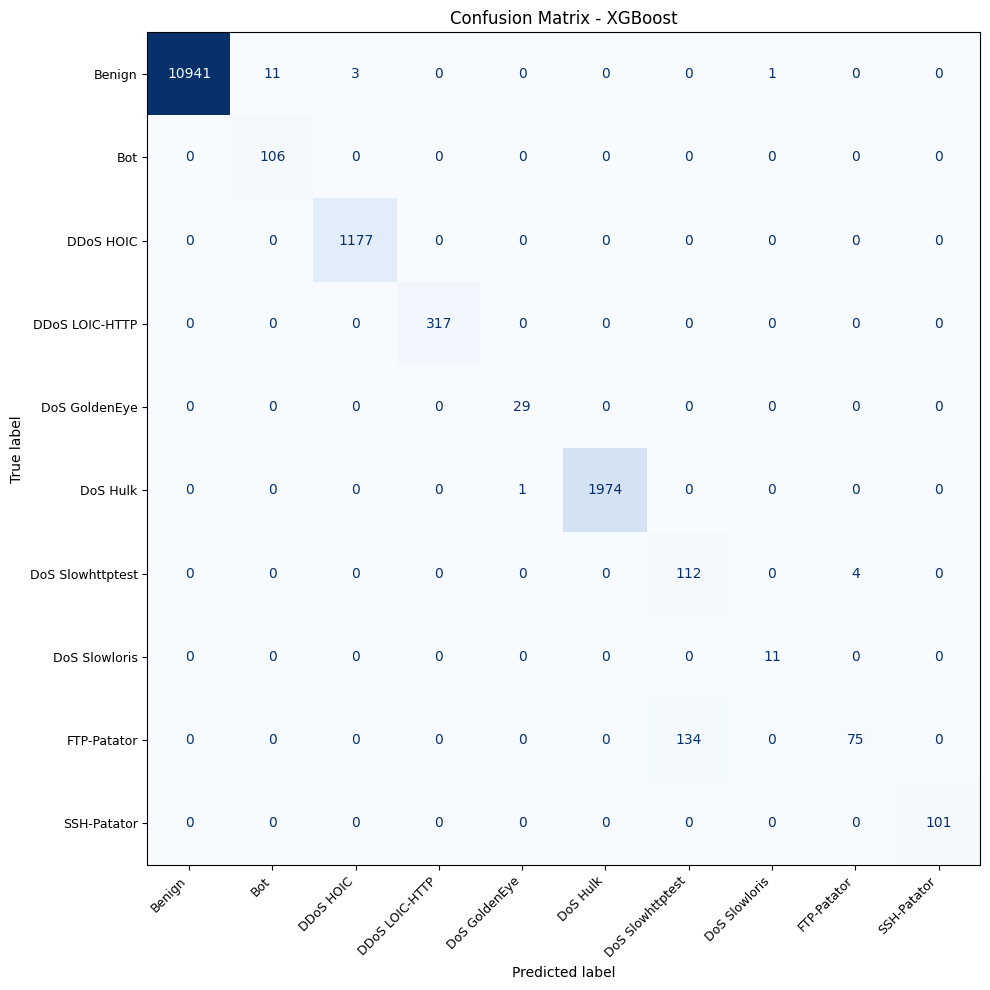

In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.metrics import (precision_recall_curve,
                             average_precision_score,
                             roc_curve, auc)
from sklearn.preprocessing import label_binarize
import torch
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_pred = xgb_model.predict(df_test_x)

# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred)



fig, ax = plt.subplots(figsize=(12, 10))  

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap='Blues', colorbar=False, ax=ax)

plt.title('Confusion Matrix - XGBoost')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)
plt.tight_layout()
plt.show()

In [16]:


y_pred = xgb_model.predict(df_test_x)
y_prob = xgb_model.predict_proba(df_test_x)

print(classification_report(
    y_test, y_pred,
    target_names=le.classes_,
    digits=4
))



                  precision    recall  f1-score   support

          Benign     1.0000    0.9986    0.9993     10956
             Bot     0.9060    1.0000    0.9507       106
       DDoS HOIC     0.9975    1.0000    0.9987      1177
  DDoS LOIC-HTTP     1.0000    1.0000    1.0000       317
   DoS GoldenEye     0.9667    1.0000    0.9831        29
        DoS Hulk     1.0000    0.9995    0.9997      1975
DoS Slowhttptest     0.4553    0.9655    0.6188       116
   DoS Slowloris     0.9167    1.0000    0.9565        11
     FTP-Patator     0.9494    0.3589    0.5208       209
     SSH-Patator     1.0000    1.0000    1.0000       101

        accuracy                         0.9897     14997
       macro avg     0.9191    0.9322    0.9028     14997
    weighted avg     0.9941    0.9897    0.9893     14997



--------------------------------------------------------------------------
Tab Transformer
--------------------------------------

Device: cuda
Features: 56, Classes: 10
Train batches: 274 | Val batches: 59 | Test batches: 59
Output shape: torch.Size([256, 10])
Trainable parameters: 281,930
Class weights: tensor([  0.1369,  14.2530,   1.2740,   4.7317,  51.0818,   0.7592,  12.9837, 132.0415,   7.1998,  14.7953], device='cuda:0')
Epoch 01/50 | Train Loss: 0.3156 F1: 0.6251 | Val Loss: 0.1525 F1: 0.8706 AUC: 0.9995
Epoch 02/50 | Train Loss: 0.1755 F1: 0.8188 | Val Loss: 0.1612 F1: 0.8433 AUC: 0.9996
Epoch 03/50 | Train Loss: 0.1533 F1: 0.8294 | Val Loss: 0.1276 F1: 0.8425 AUC: 0.9998
Epoch 04/50 | Train Loss: 0.1450 F1: 0.8434 | Val Loss: 0.1339 F1: 0.8897 AUC: 0.9997
Epoch 05/50 | Train Loss: 0.1580 F1: 0.8354 | Val Loss: 0.1353 F1: 0.8896 AUC: 0.9998
Epoch 06/50 | Train Loss: 0.1536 F1: 0.8526 | Val Loss: 0.1235 F1: 0.8856 AUC: 0.9998
Epoch 07/50 | Train Loss: 0.1431 F1: 0.8484 | Val Loss: 0.1274 F1: 0.8658 AUC: 0.9997
Epoch 08/50 | Train Loss: 0.1331 F1: 0.8687 | Val Loss: 0.1673 F1: 0.8612 AUC: 0.9996
Epoch 09/5

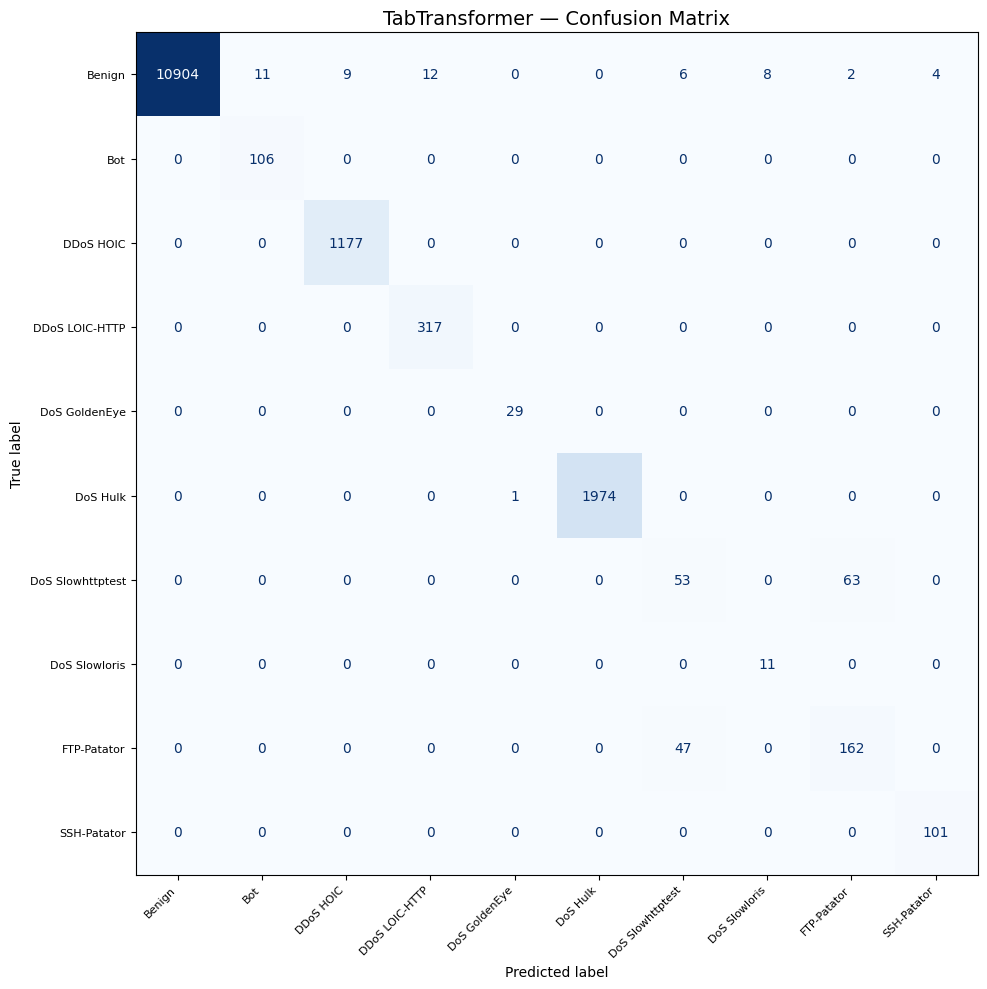

In [17]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

# ── 1. Input preparation ─────────────────────────────────────────────
X_train_arr = np.array(X_train_selected, dtype=np.float32)
X_test_arr  = np.array(X_test_selected,  dtype=np.float32)
y_train_arr = np.array(y_train, dtype=np.int64)
y_test_arr  = np.array(y_test,  dtype=np.int64)

n_features = X_train_arr.shape[1]
n_classes  = len(np.unique(y_train_arr))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
print(f"Features: {n_features}, Classes: {n_classes}")


BATCH_SIZE = 256

X_train_arr = np.array(X_train_selected, dtype=np.float32)
X_val_arr   = np.array(X_val_selected,   dtype=np.float32)
X_test_arr  = np.array(X_test_selected,  dtype=np.float32)
y_train_arr = np.array(y_train, dtype=np.int64)
y_val_arr   = np.array(y_val,   dtype=np.int64)
y_test_arr  = np.array(y_test,  dtype=np.int64)

X_train_t = torch.tensor(X_train_arr)
X_val_t   = torch.tensor(X_val_arr)
X_test_t  = torch.tensor(X_test_arr)
y_train_t = torch.tensor(y_train_arr)
y_val_t   = torch.tensor(y_val_arr)
y_test_t  = torch.tensor(y_test_arr)

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset   = TensorDataset(X_val_t,   y_val_t)
test_dataset  = TensorDataset(X_test_t,  y_test_t)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0,
    pin_memory=True if device.type == 'cuda' else False
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

print(f"Train batches: {len(train_loader)} | "
      f"Val batches: {len(val_loader)} | "
      f"Test batches: {len(test_loader)}")

class TabTransformer(nn.Module):
    def __init__(
        self,
        n_features,
        n_classes,
        embed_dim=32,
        num_heads=4,
        num_blocks=4,
        ff_dim=64,
        mlp_units=[128, 64],
        dropout=0.1,
        mlp_dropout=0.2
    ):
        super(TabTransformer, self).__init__()

        self.n_features = n_features
        self.embed_dim  = embed_dim


        self.col_embeddings = nn.ModuleList([
            nn.Linear(1, embed_dim, bias=False)
            for _ in range(n_features)
        ])

     
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation='gelu',
            batch_first=True    # (batch, seq, feature)
        )
        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_blocks
        )

        mlp_input_dim = n_features * embed_dim + n_features
        mlp_layers = []
        in_dim = mlp_input_dim
        for units in mlp_units:
            mlp_layers.extend([
                nn.Linear(in_dim, units),
                nn.GELU(),
                nn.BatchNorm1d(units),
                nn.Dropout(mlp_dropout)
            ])
            in_dim = units
        mlp_layers.append(nn.Linear(in_dim, n_classes))
        self.mlp = nn.Sequential(*mlp_layers)

    def forward(self, x):
    
        embedded = []
        for i, emb in enumerate(self.col_embeddings):
            col = x[:, i].unsqueeze(1)   
            embedded.append(emb(col).unsqueeze(1))  

        x_emb = torch.cat(embedded, dim=1) 

        
        x_t = self.transformer(x_emb)       

        
        x_flat = x_t.flatten(start_dim=1)  
        x_out  = torch.cat([x_flat, x], dim=1)  

     
        return self.mlp(x_out)



TabTransformModel = TabTransformer(
    n_features=n_features,
    n_classes=n_classes,
    embed_dim=32,
    num_heads=4,
    num_blocks=4,
    ff_dim=64,
    mlp_units=[128, 64],
    dropout=0.1,
    mlp_dropout=0.2
).to(device)


with torch.no_grad():
    test_out = TabTransformModel(torch.zeros(BATCH_SIZE, n_features).to(device))
    print(f"Output shape: {test_out.shape}")  # (256, n_classes)

total_params = sum(p.numel() for p in TabTransformModel.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,}")


class_weights = compute_class_weight(
    #class_weight='balanced',
    class_weight='balanced',
    classes=np.unique(y_train_arr),
    y=y_train_arr
)
class_weights_t = torch.tensor(class_weights, dtype=torch.float32).to(device)
print(f"Class weights: {class_weights_t}")


criterion = nn.CrossEntropyLoss(weight=class_weights_t)

optimizer = optim.Adam(
    TabTransformModel.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
   
)


from sklearn.metrics import f1_score

def train_epoch(xgb_model, loader, criterion, optimizer, device):
    xgb_model.train()
    total_loss = 0
    all_preds, all_labels = [], []

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        logits = xgb_model(X_batch)
        loss   = criterion(logits, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(xgb_model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * len(y_batch)
        all_preds.append(logits.argmax(1).cpu().numpy())
        all_labels.append(y_batch.cpu().numpy())

    all_preds  = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)

    return total_loss / len(all_labels), f1


def eval_epoch(xgb_model, loader, criterion, device):
    xgb_model.eval()
    total_loss = 0
    all_probs, all_preds, all_labels = [], [], []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = xgb_model(X_batch)
            loss   = criterion(logits, y_batch)
            probs  = torch.softmax(logits, dim=1)

            total_loss += loss.item() * len(y_batch)
            all_probs.append(probs.cpu().numpy())
            all_preds.append(logits.argmax(1).cpu().numpy())
            all_labels.append(y_batch.cpu().numpy())

    all_probs  = np.concatenate(all_probs)
    all_preds  = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    auc = roc_auc_score(all_labels, all_probs, multi_class='ovr', average='weighted')

    return total_loss / len(all_labels), f1, auc



EPOCHS       = 50
PATIENCE     = 10
best_f1      = 0.0
patience_ctr = 0
best_weights = None

for epoch in range(1, EPOCHS + 1):
    train_loss, train_f1 = train_epoch(TabTransformModel, train_loader, criterion, optimizer, device)
    val_loss, val_f1, val_auc = eval_epoch(TabTransformModel, val_loader, criterion, device)  # val only
    scheduler.step(val_f1)

    print(f"Epoch {epoch:02d}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f} F1: {train_f1:.4f} | "
          f"Val Loss: {val_loss:.4f} F1: {val_f1:.4f} AUC: {val_auc:.4f}")

    if val_f1 > best_f1:
        best_f1      = val_f1
        best_weights = {k: v.clone() for k, v in TabTransformModel.state_dict().items()}
        patience_ctr = 0
    else:
        patience_ctr += 1
        if patience_ctr >= PATIENCE:
            print(f"Early stopping at epoch {epoch}")
            break

TabTransformModel.load_state_dict(best_weights)
print(f"\nBest Val F1 Macro: {best_f1:.4f}")


print("\nEvaluating on test set...")
_, test_f1, test_auc = eval_epoch(TabTransformModel, test_loader, criterion, device)
print(f"Test F1 Macro: {test_f1:.4f}")



TabTransformModel.eval()
all_probs, all_preds, all_labels = [], [], []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        logits = TabTransformModel(X_batch.to(device))
        probs  = torch.softmax(logits, dim=1)
        preds  = logits.argmax(1)

        all_probs.append(probs.cpu().numpy())
        all_preds.append(preds.cpu().numpy())
        all_labels.append(y_batch.numpy())

all_probs  = np.concatenate(all_probs)
all_preds  = np.concatenate(all_preds)
all_labels = np.concatenate(all_labels)

print("\n" + "="*60)
print(classification_report(
    all_labels, all_preds,
    target_names=le.classes_,
    digits=4
))




from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- Confusion Matrix ---
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap='Blues', colorbar=False, ax=ax)

plt.title('TabTransformer — Confusion Matrix', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

In [6]:
y_prob_xgb  = xgb_model.predict_proba(df_test_x)  
y_pred_xgb  = xgb_model.predict(df_test_x)

NameError: name 'xgbModel' is not defined

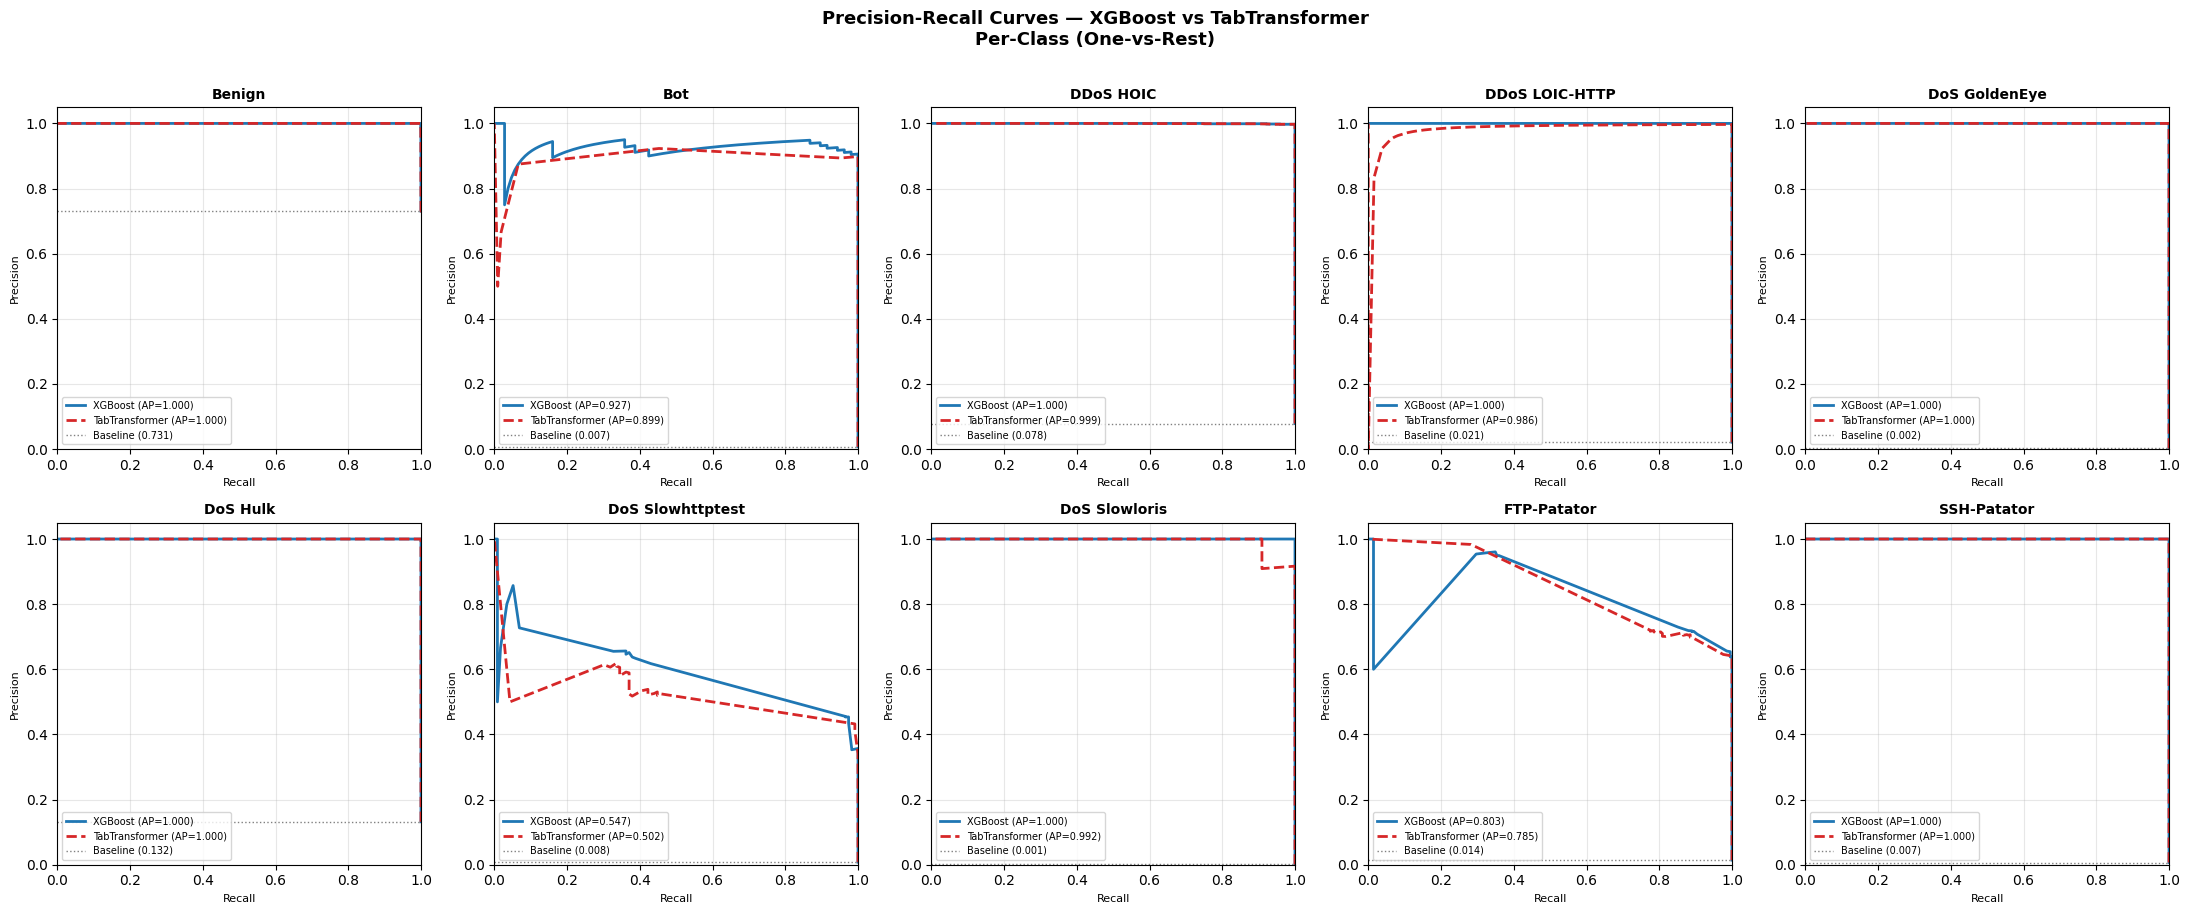

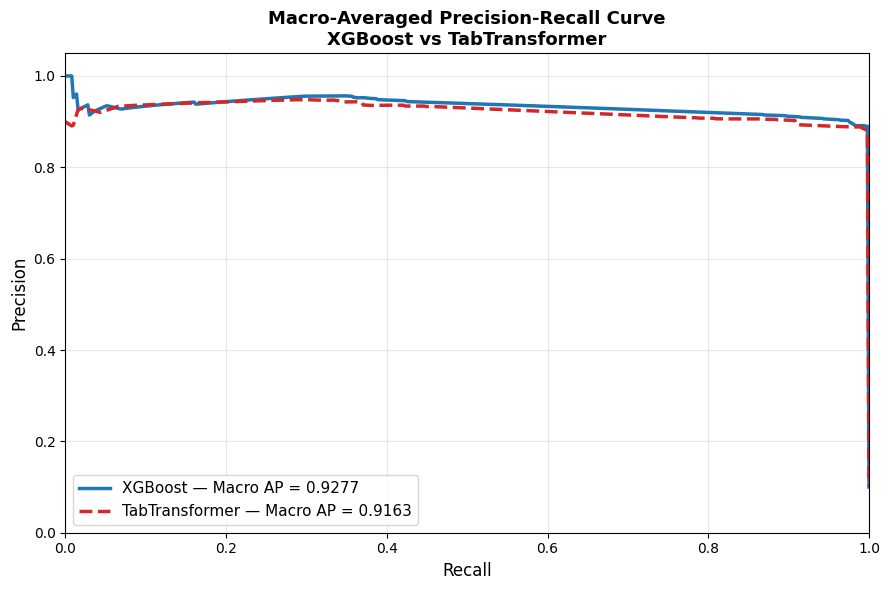

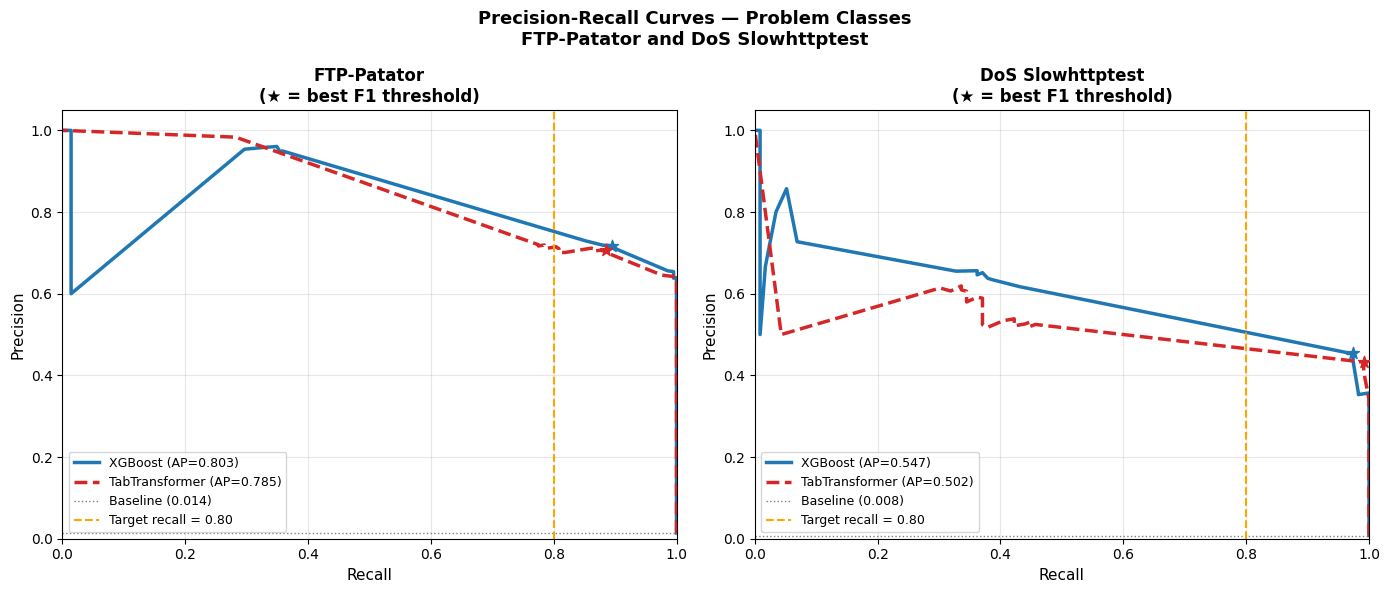


THRESHOLD ANALYSIS — Problem Classes

FTP-Patator:
xgbModel              Threshold  Precision     Recall         F1
------------------------------------------------------------
  XGBoost                0.3340     0.7165     0.8947     0.7957
    (recall≥0.80)        0.4925     0.7295     0.8517     0.7859
  TabTransformer         0.4170     0.7061     0.8852     0.7856
    (recall≥0.80)        0.5316     0.7149     0.8038     0.7568

DoS Slowhttptest:
xgbModel              Threshold  Precision     Recall         F1
------------------------------------------------------------
  XGBoost                0.4217     0.4538     0.9741     0.6192
    (recall≥0.80)        0.5046     0.4553     0.9655     0.6188
  TabTransformer         0.4291     0.4323     0.9914     0.6021
    (recall≥0.80)        0.4291     0.4323     0.9914     0.6021


AVERAGE PRECISION SUMMARY
Class                    XGBoost AP  TabTrans AP
-------------------------------------------------------
Benign                  

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.metrics import (precision_recall_curve,
                             average_precision_score,
                             roc_curve, auc)
from sklearn.preprocessing import label_binarize
import torch

TabTransformModel.eval()
all_probs_tt = []
with torch.no_grad():
    for X_batch, _ in test_loader:
        logits = TabTransformModel(X_batch.to(device))
        probs  = torch.softmax(logits, dim=1)
        all_probs_tt.append(probs.cpu().numpy())
y_prob_tt   = np.concatenate(all_probs_tt)
y_pred_tt   = np.argmax(y_prob_tt, axis=1)

#  Binarise labels for one-vs-rest curves
classes     = le.classes_
n_classes   = len(classes)
y_bin       = label_binarize(y_test, classes=np.arange(n_classes))

# 3. Per-class Precision-Recall curves 
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
axes      = axes.flatten()

colors_xgb = '#1f77b4'   # blue
colors_tt  = '#d62728'   # red

for i, cls_name in enumerate(classes):
    ax = axes[i]

    # XGBoost
    prec_xgb, rec_xgb, _ = precision_recall_curve(
        y_bin[:, i], y_prob_xgb[:, i]
    )
    ap_xgb = average_precision_score(y_bin[:, i], y_prob_xgb[:, i])

    # TabTransformer
    prec_tt, rec_tt, _ = precision_recall_curve(
        y_bin[:, i], y_prob_tt[:, i]
    )
    ap_tt = average_precision_score(y_bin[:, i], y_prob_tt[:, i])

    ax.plot(rec_xgb, prec_xgb,
            color=colors_xgb, lw=2,
            label=f'XGBoost (AP={ap_xgb:.3f})')
    ax.plot(rec_tt, prec_tt,
            color=colors_tt, lw=2, linestyle='--',
            label=f'TabTransformer (AP={ap_tt:.3f})')

    # Baseline (random classifier)
    baseline = y_bin[:, i].sum() / len(y_bin)
    ax.axhline(y=baseline, color='grey',
               linestyle=':', lw=1, label=f'Baseline ({baseline:.3f})')

    ax.set_title(cls_name, fontsize=10, fontweight='bold')
    ax.set_xlabel('Recall', fontsize=8)
    ax.set_ylabel('Precision', fontsize=8)
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.legend(fontsize=7, loc='lower left')
    ax.grid(True, alpha=0.3)

plt.suptitle('Precision-Recall Curves — XGBoost vs TabTransformer\n'
             'Per-Class (One-vs-Rest)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()

plt.show()


fig, ax = plt.subplots(figsize=(9, 6))

for model_name, y_prob, color, ls in [
    ('XGBoost',        y_prob_xgb, colors_xgb, '-'),
    ('TabTransformer', y_prob_tt,  colors_tt,  '--')
]:

    all_prec, all_rec = [], []
    for i in range(n_classes):
        prec, rec, _ = precision_recall_curve(y_bin[:, i], y_prob[:, i])
        all_prec.append(prec)
        all_rec.append(rec)

 
    mean_rec   = np.linspace(0, 1, 500)
    mean_prec  = np.zeros_like(mean_rec)
    for i in range(n_classes):
        mean_prec += np.interp(mean_rec, all_rec[i][::-1],
                               all_prec[i][::-1])
    mean_prec /= n_classes

    macro_ap = average_precision_score(y_bin, y_prob, average='macro')

    ax.plot(mean_rec, mean_prec,
            color=color, lw=2.5, linestyle=ls,
            label=f'{model_name} — Macro AP = {macro_ap:.4f}')

ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Macro-Averaged Precision-Recall Curve\n'
             'XGBoost vs TabTransformer', fontsize=13, fontweight='bold')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#Problem classes focused plot
problem_classes = ['FTP-Patator', 'DoS Slowhttptest']
problem_idx     = [list(classes).index(c) for c in problem_classes]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, cls_idx, cls_name in zip(axes, problem_idx, problem_classes):

    for model_name, y_prob, color, ls in [
        ('XGBoost',        y_prob_xgb, colors_xgb, '-'),
        ('TabTransformer', y_prob_tt,  colors_tt,  '--')
    ]:
        prec, rec, thresh = precision_recall_curve(
            y_bin[:, cls_idx], y_prob[:, cls_idx]
        )
        ap = average_precision_score(
            y_bin[:, cls_idx], y_prob[:, cls_idx]
        )
        ax.plot(rec, prec, color=color, lw=2.5, linestyle=ls,
                label=f'{model_name} (AP={ap:.3f})')

        # Mark F1=0.5 operating point
        f1_scores = 2 * prec * rec / (prec + rec + 1e-8)
        best_idx  = np.argmax(f1_scores)
        ax.scatter(rec[best_idx], prec[best_idx],
                   color=color, s=80, zorder=5,
                   marker='*')

    baseline = y_bin[:, cls_idx].sum() / len(y_bin)
    ax.axhline(y=baseline, color='grey', linestyle=':', lw=1,
               label=f'Baseline ({baseline:.3f})')
    ax.axvline(x=0.80, color='orange', linestyle='--', lw=1.5,
               label='Target recall = 0.80')

    ax.set_title(f'{cls_name}\n(★ = best F1 threshold)',
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('Recall', fontsize=11)
    ax.set_ylabel('Precision', fontsize=11)
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Precision-Recall Curves — Problem Classes\n'
             'FTP-Patator and DoS Slowhttptest',
             fontsize=13, fontweight='bold')
plt.tight_layout()

plt.show()


print("\nTHRESHOLD ANALYSIS — Problem Classes")
print("=" * 70)

for cls_idx, cls_name in zip(problem_idx, problem_classes):
    print(f"\n{cls_name}:")
    print(f"{'xgb_model':<20} {'Threshold':>10} {'Precision':>10} "
          f"{'Recall':>10} {'F1':>10}")
    print("-" * 60)

    for model_name, y_prob in [('XGBoost', y_prob_xgb),
                                ('TabTransformer', y_prob_tt)]:
        prec, rec, thresh = precision_recall_curve(
            y_bin[:, cls_idx], y_prob[:, cls_idx]
        )
        f1 = 2 * prec * rec / (prec + rec + 1e-8)

        # Best F1 threshold
        best = np.argmax(f1)
        print(f"  {model_name:<18} {thresh[best]:>10.4f} "
              f"{prec[best]:>10.4f} {rec[best]:>10.4f} "
              f"{f1[best]:>10.4f}")

        # Threshold for recall >= 0.80
        valid = np.where(rec[:-1] >= 0.80)[0]
        if len(valid) > 0:
            idx_80 = valid[np.argmax(prec[valid])]
            print(f"  {'  (recall≥0.80)':<18} {thresh[idx_80]:>10.4f} "
                  f"{prec[idx_80]:>10.4f} {rec[idx_80]:>10.4f} "
                  f"{f1[idx_80]:>10.4f}")


print("\n\nAVERAGE PRECISION SUMMARY")
print("=" * 55)
print(f"{'Class':<22} {'XGBoost AP':>12} {'TabTrans AP':>12}")
print("-" * 55)

for i, cls_name in enumerate(classes):
    ap_xgb = average_precision_score(y_bin[:, i], y_prob_xgb[:, i])
    ap_tt  = average_precision_score(y_bin[:, i], y_prob_tt[:, i])
    better = "←" if ap_xgb > ap_tt else "  ←" if ap_tt > ap_xgb else ""
    print(f"{cls_name:<22} {ap_xgb:>12.4f} {ap_tt:>12.4f} {better}")

macro_ap_xgb = average_precision_score(y_bin, y_prob_xgb, average='macro')
macro_ap_tt  = average_precision_score(y_bin, y_prob_tt,  average='macro')
print("-" * 55)
print(f"{'Macro Average':<22} {macro_ap_xgb:>12.4f} {macro_ap_tt:>12.4f}")

------------------------------------------------------------------------------------
Storage 
------------------------------------------------------------------------------------

In [20]:
import os
import joblib
import numpy as np
import torch

iskaggle = os.environ.get('KAGGLE_KERNEL_RUN_TYPE', '')
if iskaggle: ARTIFACT_DIR = '/kaggle/output' #Change username and file path if using kaggle
else: ARTIFACT_DIR = 'Artefacts' #Otherwise use default dir

#SAVING OF ARTEFACTS
np.save(f'{ARTIFACT_DIR}/rfe_support_mask_macro.npy',
        rfe_mask)
np.save(f'{ARTIFACT_DIR}/scaler_mean.npy',
        pipe['scaler'].mean_)
np.save(f'{ARTIFACT_DIR}/scaler_scale.npy',
        pipe['scaler'].scale_)
np.save(f'{ARTIFACT_DIR}/feature_names_protected.npy',
        np.array(features_name, dtype=object))
joblib.dump(le, f'{ARTIFACT_DIR}/label_encoder.pkl')

# XGBoost
xgb_model.save_model(f'{ARTIFACT_DIR}/xgb_macro_features.json')

#Tab Transformer
torch.save({
    'model_state_dict':  TabTransformModel.state_dict(),
    'n_features':        n_features,
    'n_classes':         n_classes,
    'embed_dim':         32,
    'num_heads':         4,
    'num_blocks':        4,
    'ff_dim':            64,
    'mlp_units':         [128, 64],
    'dropout':           0.1,
    'mlp_dropout':       0.2,
    'features_name':     features_name,
    'best_val_f1_macro': best_f1,
}, f'{ARTIFACT_DIR}/tabtransformer_pytorch.pt')


files = [
    'rfe_support_mask_macro.npy',
    'scaler_mean.npy',
    'scaler_scale.npy',
    'feature_names_protected.npy',
    'label_encoder.pkl',
    'xgb_macro_features.json',
    'tabtransformer_pytorch.pt',
]

print("Artifact verification:")
for f in files:
    path = f'{ARTIFACT_DIR}/{f}'
    size = os.path.getsize(path) if os.path.exists(path) else 0
    status = " Found" if size > 0 else " MISSING"
    print(f"  {status}  {f}  ({size:,} bytes)")

import zipfile

zip_path = f'{ARTIFACT_DIR}/ids_artifacts.zip'

files = [
    'rfe_support_mask_macro.npy',
    'scaler_mean.npy',
    'scaler_scale.npy',
    'feature_names_protected.npy',
    'label_encoder.pkl',
    'xgb_macro_features.json',
    'tabtransformer_pytorch.pt',
]

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in files:
        fpath = f'{ARTIFACT_DIR}/{fname}'
        if os.path.exists(fpath):
            zf.write(fpath, fname)
            print(f"  added to archive: {fname}")
        else:
            print(f"  MISSING: {fname}")

size_mb = os.path.getsize(zip_path) / 1024 / 1024
print(f"\nids_artifacts.zip  ({size_mb:.1f} MB)")
print("Ready for download")

Artifact verification:
   Found  rfe_support_mask_macro.npy  (205 bytes)
   Found  scaler_mean.npy  (744 bytes)
   Found  scaler_scale.npy  (744 bytes)
   Found  feature_names_protected.npy  (1,162 bytes)
   Found  label_encoder.pkl  (607 bytes)
   Found  xgb_macro_features.json  (2,895,827 bytes)
   Found  tabtransformer_pytorch.pt  (1,175,985 bytes)
  added to archive: rfe_support_mask_macro.npy
  added to archive: scaler_mean.npy
  added to archive: scaler_scale.npy
  added to archive: feature_names_protected.npy
  added to archive: label_encoder.pkl
  added to archive: xgb_macro_features.json
  added to archive: tabtransformer_pytorch.pt

ids_artifacts.zip  (1.7 MB)
Ready for download


In [21]:
#SAVE FOR FEATURES AND DATA SPLITS
# ── Save sampled dataset and all three splits ─────────────────────────
import os




combined = X.copy()
combined['label'] = y
combined.to_parquet(f'{ARTIFACT_DIR}/sampled_dataset.parquet', index=False)

# The three splits as separate files
# Saving X as DataFrames and y as numpy arrays
X_train.to_parquet(f'{ARTIFACT_DIR}/X_train.parquet', index=False)
X_val.to_parquet(  f'{ARTIFACT_DIR}/X_val.parquet',   index=False)
X_test.to_parquet( f'{ARTIFACT_DIR}/X_test.parquet',  index=False)

np.save(f'{ARTIFACT_DIR}/y_train.npy', y_train)
np.save(f'{ARTIFACT_DIR}/y_val.npy',   y_val)
np.save(f'{ARTIFACT_DIR}/y_test.npy',  y_test)

# Verify
files = [
    'sampled_dataset.parquet',
    'X_train.parquet', 'X_val.parquet', 'X_test.parquet',
    'y_train.npy',     'y_val.npy',     'y_test.npy',
]
print("Dataset verification:")
for f in files:
    path = f'{ARTIFACT_DIR}/{f}'
    size = os.path.getsize(path) / 1024 / 1024
    print(f"  Saved:  {f}  ({size:.1f} MB)")

Dataset verification:
  Saved:  sampled_dataset.parquet  (14.3 MB)
  Saved:  X_train.parquet  (10.7 MB)
  Saved:  X_val.parquet  (2.4 MB)
  Saved:  X_test.parquet  (2.4 MB)
  Saved:  y_train.npy  (0.5 MB)
  Saved:  y_val.npy  (0.1 MB)
  Saved:  y_test.npy  (0.1 MB)


In [22]:
import zipfile
import os


dataset_files = [
    'sampled_dataset.parquet',
    'X_train.parquet',
    'X_val.parquet',
    'X_test.parquet',
    'y_train.npy',
    'y_val.npy',
    'y_test.npy',
]

zip_path = f'{ARTIFACT_DIR}/loadedset_dataset.zip'

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in dataset_files:
        fpath = f'{ARTIFACT_DIR}/{fname}'
        if os.path.exists(fpath):
            zf.write(fpath, fname)
            print(f"  added: {fname}")
        else:
            print(f"  MISSING: {fname}")

size_mb = os.path.getsize(zip_path) / 1024 / 1024
print(f"loadedset_dataset.zip  ({size_mb:.1f} MB)")
print("Ready")

  added: sampled_dataset.parquet
  added: X_train.parquet
  added: X_val.parquet
  added: X_test.parquet
  added: y_train.npy
  added: y_val.npy
  added: y_test.npy
loadedset_dataset.zip  (25.7 MB)
Ready


Deployment
-------------------------------------------------

In [1]:

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import joblib
import os
import gc
import warnings
from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFECV
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import (compute_sample_weight,
                                         compute_class_weight)
from sklearn.metrics import (classification_report,
                             confusion_matrix,
                             ConfusionMatrixDisplay,
                             roc_auc_score,
                             matthews_corrcoef,
                             f1_score)

iskaggle = os.environ.get('KAGGLE_KERNEL_RUN_TYPE', '')
if iskaggle: ARTIFACT_DIR = '/kaggle/input/models/username/nids/pytorch/default/3' #Change username and file path if using Kaggle
else: ARTIFACT_DIR = 'Artefacts' #Otherwise use default dir

In [2]:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from torch.utils.data import DataLoader, TensorDataset
from xgboost import XGBClassifier

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")


import zipfile, os


ARTIFACT_ZIP = ARTIFACT_DIR+'/ids_artifacts.zip'
DATASET_ZIP  = ARTIFACT_DIR+'/loadset_dataset.zip'

if os.path.exists(ARTIFACT_ZIP):
    with zipfile.ZipFile(ARTIFACT_ZIP, 'r') as z:
        z.extractall(ARTIFACT_DIR)
    print("Artifacts extracted ")

if os.path.exists(DATASET_ZIP):
    with zipfile.ZipFile(DATASET_ZIP, 'r') as z:
        z.extractall(ARTIFACT_DIR)
    print("Dataset extracted ")



features_name = np.load(
    f'{ARTIFACT_DIR}/feature_names_protected.npy',
    allow_pickle=True
).tolist()

le = joblib.load(f'{ARTIFACT_DIR}/label_encoder.pkl')

scaler                = StandardScaler()
scaler.mean_          = np.load(f'{ARTIFACT_DIR}/scaler_mean.npy')
scaler.scale_         = np.load(f'{ARTIFACT_DIR}/scaler_scale.npy')
scaler.var_           = scaler.scale_ ** 2
scaler.n_features_in_ = len(scaler.mean_)

n_features = len(features_name)
n_classes  = len(le.classes_)

print(f"Features:  {n_features}")
print(f"Classes:   {list(le.classes_)}")
print("Preprocessing loaded ")


X_train = pd.read_parquet(f'{ARTIFACT_DIR}/X_train.parquet')
X_val   = pd.read_parquet(f'{ARTIFACT_DIR}/X_val.parquet')
X_test  = pd.read_parquet(f'{ARTIFACT_DIR}/X_test.parquet')

y_train = np.load(f'{ARTIFACT_DIR}/y_train.npy')
y_val   = np.load(f'{ARTIFACT_DIR}/y_val.npy')
y_test  = np.load(f'{ARTIFACT_DIR}/y_test.npy')

print(f"X_train: {X_train.shape}  y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}    y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape}   y_test:  {y_test.shape}")




def build_scaled_df(X_raw):
    # Step 1 — scale all 77 columns
    X_scaled_all = scaler.transform(X_raw)
    X_scaled_df  = pd.DataFrame(X_scaled_all, columns=X_raw.columns)
    # Step 2 — select the 56 RFECV columns
    return X_scaled_df[features_name].reset_index(drop=True)

df_x_train = build_scaled_df(X_train)
df_x_val   = build_scaled_df(X_val)
df_test_x  = build_scaled_df(X_test)

X_train_arr = df_x_train.values.astype(np.float32)
X_val_arr   = X_val_arr  = df_x_val.values.astype(np.float32)
X_test_arr  = df_test_x.values.astype(np.float32)
y_train_arr = y_train.astype(np.int64)
y_val_arr   = y_val.astype(np.int64)
y_test_arr  = y_test.astype(np.int64)

print(f"df_x_train: {df_x_train.shape}")
print(f"df_x_val:   {df_x_val.shape}")
print(f"df_test_x:  {df_test_x.shape}")
print("Scaled DataFrames ready ")



xgb_model = XGBClassifier()
xgb_model.load_model(f'{ARTIFACT_DIR}/xgb_macro_features.json')
print(f"XGBoost loaded   ({xgb_model.n_features_in_} features)")



class TabTransformer(nn.Module):
    def __init__(self, n_features, n_classes,
                 embed_dim=32, num_heads=4, num_blocks=4,
                 ff_dim=64, mlp_units=[128, 64],
                 dropout=0.1, mlp_dropout=0.2):
        super().__init__()
        self.col_embeddings = nn.ModuleList([
            nn.Linear(1, embed_dim, bias=False)
            for _ in range(n_features)
        ])
        enc = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads,
            dim_feedforward=ff_dim, dropout=dropout,
            activation='gelu', batch_first=True
        )
        self.transformer = nn.TransformerEncoder(enc, num_layers=num_blocks)
        in_dim = n_features * embed_dim + n_features
        layers = []
        for u in mlp_units:
            layers += [nn.Linear(in_dim, u), nn.GELU(),
                       nn.BatchNorm1d(u), nn.Dropout(mlp_dropout)]
            in_dim = u
        layers.append(nn.Linear(in_dim, n_classes))
        self.mlp = nn.Sequential(*layers)

    def forward(self, x):
        embs  = [emb(x[:, i].unsqueeze(1)).unsqueeze(1)
                 for i, emb in enumerate(self.col_embeddings)]
        x_emb = torch.cat(embs, dim=1)
        x_t   = self.transformer(x_emb)
        x_out = torch.cat([x_t.flatten(start_dim=1), x], dim=1)
        return self.mlp(x_out)

ckpt     = torch.load(f'{ARTIFACT_DIR}/tabtransformer_pytorch.pt',
                      map_location=device)
TabTransformModel = TabTransformer(
    n_features  = ckpt['n_features'],
    n_classes   = ckpt['n_classes'],
    embed_dim   = ckpt['embed_dim'],
    num_heads   = ckpt['num_heads'],
    num_blocks  = ckpt['num_blocks'],
    ff_dim      = ckpt['ff_dim'],
    mlp_units   = ckpt['mlp_units'],
    dropout     = ckpt['dropout'],
    mlp_dropout = ckpt['mlp_dropout'],
)
TabTransformModel.load_state_dict(ckpt['model_state_dict'])
TabTransformModel.eval().to(device)
print(f"TabTransformer loaded   (best val F1: {ckpt['best_val_f1_macro']:.4f})")



BATCH_SIZE = 256

def make_loader(X_arr, y_arr, shuffle):
    ds = TensorDataset(
        torch.tensor(X_arr),
        torch.tensor(y_arr)
    )
    return DataLoader(ds, batch_size=BATCH_SIZE,
                      shuffle=shuffle, num_workers=0,
                      pin_memory=(device.type == 'cuda'))

train_loader = make_loader(X_train_arr, y_train_arr, shuffle=True)
val_loader   = make_loader(X_val_arr,   y_val_arr,   shuffle=False)
test_loader  = make_loader(X_test_arr,  y_test_arr,  shuffle=False)

print("DataLoaders ready ")
print(f"  Train batches: {len(train_loader)}")
print(f"  Val batches:   {len(val_loader)}")
print(f"  Test batches:  {len(test_loader)}")


# ══════════════════════════════════════════════════════════════════════
# CELL 9 — Verify: quick test prediction from both models
# ══════════════════════════════════════════════════════════════════════
from sklearn.metrics import f1_score

# XGBoost
y_xgb_pred = xgb_model.predict(df_test_x)
f1_xgb     = f1_score(y_test, y_xgb_pred, average='macro')
print(f"XGBoost       macro F1: {f1_xgb:.4f}")

# TabTransformer
all_preds = []
with torch.no_grad():
    for X_batch, _ in test_loader:
        logits = TabTransformModel(X_batch.to(device))
        all_preds.append(logits.argmax(1).cpu().numpy())

y_tt_pred = np.concatenate(all_preds)
f1_tt     = f1_score(y_test, y_tt_pred, average='macro')
print(f"TabTransformer macro F1: {f1_tt:.4f}")

print("\nRedeploy complete   — all variables ready for inference cells")

Device: cuda
Features:  56
Classes:   ['Benign', 'Bot', 'DDoS HOIC', 'DDoS LOIC-HTTP', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS Slowloris', 'FTP-Patator', 'SSH-Patator']
Preprocessing loaded 


C:\Python314\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.6.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


X_train: (69982, 77)  y_train: (69982,)
X_val:   (14996, 77)    y_val:   (14996,)
X_test:  (14997, 77)   y_test:  (14997,)
df_x_train: (69982, 56)
df_x_val:   (14996, 56)
df_test_x:  (14997, 56)
Scaled DataFrames ready 


C:\Python314\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Python314\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Python314\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


XGBoost loaded   (56 features)
TabTransformer loaded   (best val F1: 0.9205)
DataLoaders ready 
  Train batches: 274
  Val batches:   59
  Test batches:  59
XGBoost       macro F1: 0.9028
TabTransformer macro F1: 0.8954

Redeploy complete   — all variables ready for inference cells



═════════════════════════════════════════════════════════════════
  XGBoost
═════════════════════════════════════════════════════════════════
  F1 Macro   : 0.9028  ← primary metric
  F1 Weighted: 0.9893
  MCC        : 0.9770
  AUC Macro  : 0.9994

                  precision    recall  f1-score   support

          Benign     1.0000    0.9986    0.9993     10956
             Bot     0.9060    1.0000    0.9507       106
       DDoS HOIC     0.9975    1.0000    0.9987      1177
  DDoS LOIC-HTTP     1.0000    1.0000    1.0000       317
   DoS GoldenEye     0.9667    1.0000    0.9831        29
        DoS Hulk     1.0000    0.9995    0.9997      1975
DoS Slowhttptest     0.4553    0.9655    0.6188       116
   DoS Slowloris     0.9167    1.0000    0.9565        11
     FTP-Patator     0.9494    0.3589    0.5208       209
     SSH-Patator     1.0000    1.0000    1.0000       101

        accuracy                         0.9897     14997
       macro avg     0.9191    0.9322    0.9028     

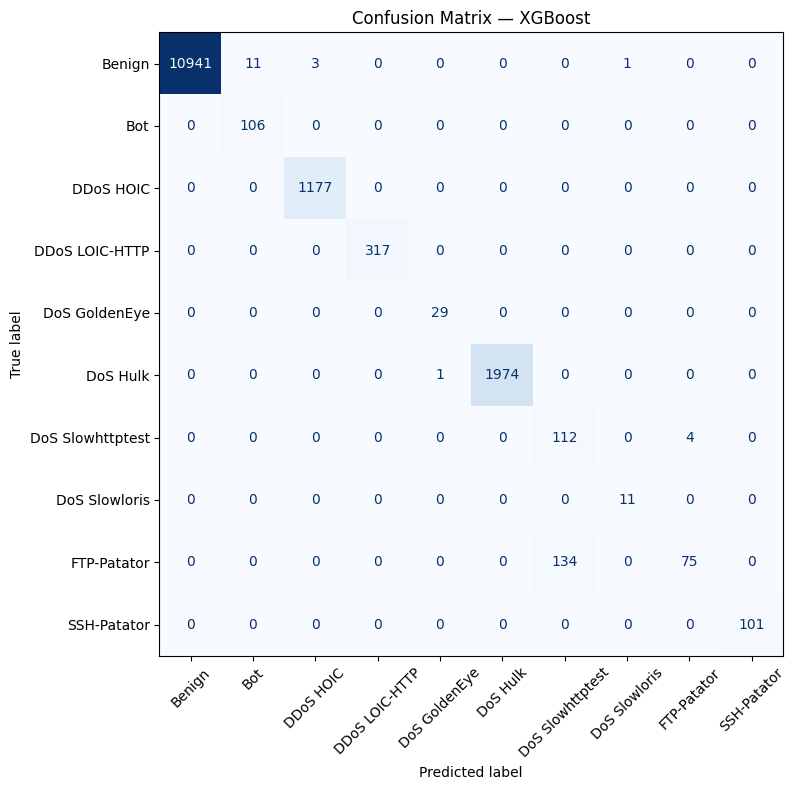


═════════════════════════════════════════════════════════════════
  TabTransformer
═════════════════════════════════════════════════════════════════
  F1 Macro   : 0.8954  ← primary metric
  F1 Weighted: 0.9907
  MCC        : 0.9800
  AUC Macro  : 0.9993

                  precision    recall  f1-score   support

          Benign     1.0000    0.9974    0.9987     10956
             Bot     0.8833    1.0000    0.9381       106
       DDoS HOIC     0.9975    1.0000    0.9987      1177
  DDoS LOIC-HTTP     0.9906    1.0000    0.9953       317
   DoS GoldenEye     0.9667    1.0000    0.9831        29
        DoS Hulk     1.0000    0.9995    0.9997      1975
DoS Slowhttptest     0.5797    0.3448    0.4324       116
   DoS Slowloris     0.7333    1.0000    0.8462        11
     FTP-Patator     0.7043    0.8660    0.7768       209
     SSH-Patator     0.9712    1.0000    0.9854       101

        accuracy                         0.9911     14997
       macro avg     0.8827    0.9208    0.89

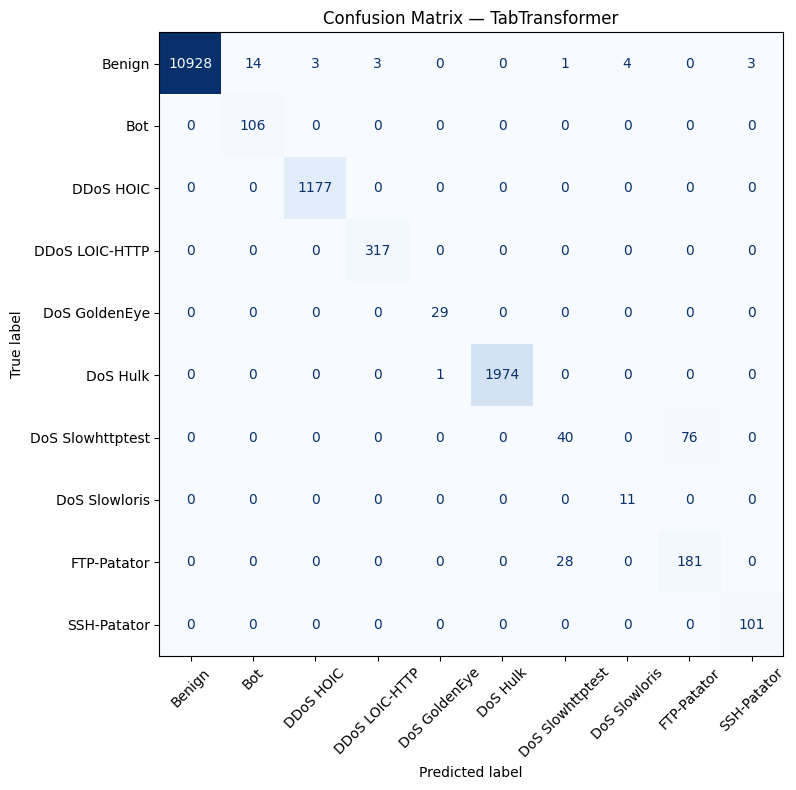


═══════════════════════════════════════════════════════════════════════════
  FINAL COMPARISON
═══════════════════════════════════════════════════════════════════════════
  xgb_model                   F1 Macro  F1 Weighted      MCC  AUC Macro
  -----------------------------------------------------------------
  XGBoost                       0.9028       0.9893   0.9770     0.9994
  TabTransformer                0.8954       0.9907   0.9800     0.9993

  xgb_model                  FTP-Patator F1  DoS Slowhttp F1
  ----------------------------------------------------------
  XGBoost                            0.5208           0.6188
  TabTransformer                     0.7768           0.4324
═══════════════════════════════════════════════════════════════════════════


In [3]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
)


def evaluate(model_name, y_true, y_pred, y_prob):
    f1_mac = f1_score(y_true, y_pred, average='macro',    zero_division=0)
    f1_w   = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    mcc    = matthews_corrcoef(y_true, y_pred)
    auc    = roc_auc_score(y_true, y_prob,
                           multi_class='ovr', average='macro')

    print(f"\n{'═'*65}")
    print(f"  {model_name}")
    print(f"{'═'*65}")
    print(f"  F1 Macro   : {f1_mac:.4f}  ← primary metric")
    print(f"  F1 Weighted: {f1_w:.4f}")
    print(f"  MCC        : {mcc:.4f}")
    print(f"  AUC Macro  : {auc:.4f}")
    print(f"\n{classification_report(y_true, y_pred,
          target_names=le.classes_, digits=4)}")

    # Confusion matrix
    cm   = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=le.classes_
    ).plot(cmap='Blues', colorbar=False, ax=ax, xticks_rotation=45)
    ax.set_title(f'Confusion Matrix — {model_name}')
    plt.tight_layout()
    fname = f"{ARTIFACT_DIR}/cm_{model_name.replace(' ', '_')}.png"
    plt.show()
  
    return {
        'xgb_model':      model_name,
        'f1_macro':   f1_mac,
        'f1_weighted': f1_w,
        'mcc':        mcc,
        'auc_macro':  auc,
        'y_pred':     y_pred,
        'y_prob':     y_prob,
    }


# XGBoost 
y_prob_xgb = xgb_model.predict_proba(df_test_x)
y_pred_xgb = np.argmax(y_prob_xgb, axis=1)

results_xgb = evaluate('XGBoost', y_test, y_pred_xgb, y_prob_xgb)


# TabTransformer 
TabTransformModel.eval()
all_preds, all_probs = [], []

with torch.no_grad():
    for X_batch, _ in test_loader:
        logits = TabTransformModel(X_batch.to(device))
        probs  = torch.softmax(logits, dim=1).cpu().numpy()
        preds  = np.argmax(probs, axis=1)
        all_preds.append(preds)
        all_probs.append(probs)

y_pred_tt = np.concatenate(all_preds)
y_prob_tt = np.concatenate(all_probs)

results_tt = evaluate('TabTransformer', y_test, y_pred_tt, y_prob_tt)


print(f"\n{'═'*75}")
print("  FINAL COMPARISON")
print(f"{'═'*75}")
print(f"  {'xgb_model':<25} {'F1 Macro':>10} {'F1 Weighted':>12} "
      f"{'MCC':>8} {'AUC Macro':>10}")
print(f"  {'-'*65}")

for r in [results_xgb, results_tt]:
    print(f"  {r['xgb_model']:<25} {r['f1_macro']:>10.4f} "
          f"{r['f1_weighted']:>12.4f} {r['mcc']:>8.4f} "
          f"{r['auc_macro']:>10.4f}")

print(f"\n  {'xgb_model':<25} {'FTP-Patator F1':>15} {'DoS Slowhttp F1':>16}")
print(f"  {'-'*58}")

for r in [results_xgb, results_tt]:
    rep  = classification_report(
        y_test, r['y_pred'],
        target_names=le.classes_,
        output_dict=True, zero_division=0
    )
    ftp  = rep.get('FTP-Patator',      {}).get('f1-score', 0.0)
    slow = rep.get('DoS Slowhttptest', {}).get('f1-score', 0.0)
    print(f"  {r['xgb_model']:<25} {ftp:>15.4f} {slow:>16.4f}")

print(f"{'═'*75}")